# 고객 이탈 예측 2 — 평가용 데이터의 순열 특성 중요도 (`permutation_importance`)

수업 필기 `고객이탈예측 2` 와 메모(`딥러닝_1일.txt` 앞부분)를 **실행 가능하도록 정리 · 개선한 노트**입니다.
(교재 `모델검증및평가` 18장 — 특성 중요도 · 과적합 판정)

- 전처리 · EDA · 로지스틱 회귀 / SVM / 결정 트리 고도화는 [Day 030 `churn_model_evaluation.ipynb`](../../2026-10-21/lecture/churn_model_evaluation.ipynb) 에 단계별로 정리했습니다. 이 노트는 필기에 새로 추가된 **평가용 데이터의 순열 특성 중요도** 부분입니다.
- 원본에서 고친 부분은 **📝 고친 부분** 으로 따로 적어 두었습니다.

In [1]:
# 그래프 한글 폰트 설정 (운영체제별)
import platform
import matplotlib.pyplot as plt

if platform.system() == 'Windows':
    plt.rcParams['font.family'] = 'Malgun Gothic'
elif platform.system() == 'Darwin':
    plt.rcParams['font.family'] = 'AppleGothic'
plt.rcParams['axes.unicode_minus'] = False

## 1. 데이터 준비 (Day 030 과 같은 전처리)

In [2]:
import time
import warnings
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv('./Telco-Customer-Churn.csv')
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')   # 공백 ' ' → NaN
df1 = df.dropna(ignore_index=True)                                         # 7,043 → 7,032명
df2 = df1.drop(columns=['customerID'])
df2['Churn'] = df2['Churn'].map({'No': 0, 'Yes': 1})

categorical_cols = df2.select_dtypes(include=['object', 'string']).columns.tolist()
df_onehot = pd.get_dummies(df2, columns=categorical_cols, dtype=int)       # 특성 45개

X_data = df_onehot.drop(columns=['Churn'])
y_data = df_onehot['Churn']
X_train, X_test, y_train, y_test = train_test_split(
    X_data, y_data, test_size=0.2, random_state=0, stratify=y_data)
print("학습용 :", X_train.shape, " 평가용 :", X_test.shape)

학습용 : (5625, 45)  평가용 : (1407, 45)


## 2. 필기의 best 모델 — `C=1, max_iter=500`

필기에서 `GridSearchCV`(`C` × `max_iter`, `scoring='f1'`)가 고른 조합으로 다시 만든 모델(`best_lr1`). 스케일링을 하지 않아 이번에도 **수렴하지 못한다**([Day 030](../../2026-10-21/) 참고).

In [3]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, f1_score

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter('always')
    best_lr = LogisticRegression(C=1, max_iter=500, random_state=0).fit(X_train, y_train)
print("경고 :", {w.category.__name__ for w in caught}, " 반복 :", best_lr.n_iter_)

pred_test = best_lr.predict(X_test)
print(classification_report(y_test, pred_test, digits=3))

경고 : {'ConvergenceWarning'}  반복 : [500]
              precision    recall  f1-score   support

           0      0.848     0.900     0.873      1033
           1      0.668     0.553     0.605       374

    accuracy                          0.808      1407
   macro avg      0.758     0.727     0.739      1407
weighted avg      0.800     0.808     0.802      1407



## 3. 순열 특성 중요도 — `permutation_importance()`

**학습이 끝난 모델**에 평가용 데이터를 넣되, **컬럼 하나의 값만 무작위로 섞어서** 성능이 얼마나 떨어지는지 잰다. 많이 떨어질수록 그 컬럼에 많이 의존한다.

| 매개변수 | 의미 |
|---|---|
| `estimator` | 학습이 끝난 모델 |
| `X`, `y` | 중요도를 잴 데이터 — **평가용** (`X_test`, `y_test`) |
| `scoring` | 떨어지는 양을 잴 지표 (`'f1'`, `'accuracy'` …, 생략하면 모델의 `score` = 정확도) |
| `n_repeats` | 컬럼마다 **몇 번 섞을지** — 섞을 때마다 결과가 달라서 여러 번 평균 |
| `random_state` | 섞는 순서 고정 (재현성) |
| `n_jobs` | 병렬 처리 (`-1` = CPU 코어 모두) |

In [4]:
from sklearn.inspection import permutation_importance

lr_perm_result = permutation_importance(
    estimator=best_lr,
    X=X_test,
    y=y_test,
    scoring='f1',        # 섞었을 때 F1 이 얼마나 떨어지나
    n_repeats=5,         # 컬럼마다 5번씩 섞기 → 45개 × 5번 = 225번 예측
    random_state=0,
)
print(type(lr_perm_result))
print(list(lr_perm_result.keys()))

<class 'sklearn.utils._bunch.Bunch'>
['importances_mean', 'importances_std', 'importances']


결과는 **`Bunch`** — 딕셔너리처럼도, 속성처럼도 꺼낼 수 있는 sklearn 의 자료형이다(`load_iris()` 의 결과와 같다). 메모의 "키 가져오는 방법 2가지(딕셔너리, 번치)" 가 이것.

In [5]:
# 방법 1 : 딕셔너리처럼 ['키']
print(lr_perm_result['importances_mean'][:3])
# 방법 2 : 번치(Bunch)의 속성처럼 .키
print(lr_perm_result.importances_mean[:3])

print("importances 모양 :", lr_perm_result.importances.shape, " ← (특성 45개, 섞은 횟수 5번)")
print("importances_mean = 5번의 평균, importances_std = 5번의 표준편차")

[0.00915811 0.25205124 0.00220052]
[0.00915811 0.25205124 0.00220052]
importances 모양 : (45, 5)  ← (특성 45개, 섞은 횟수 5번)
importances_mean = 5번의 평균, importances_std = 5번의 표준편차


In [6]:
# 컬럼 이름 + 평균 · 표준편차 → DataFrame → 내림차순
df_test_lr_test_imp = pd.DataFrame({
    'feature': X_test.columns,
    'importances': lr_perm_result.importances_mean,
    'std': lr_perm_result.importances_std,
}).sort_values(by='importances', ascending=False)

print("음수(섞었더니 오히려 좋아진) 특성 :", int((df_test_lr_test_imp['importances'] < 0).sum()), "개")
df_test_lr_test_imp.head(10).round(4)

음수(섞었더니 오히려 좋아진) 특성 : 27 개


,feature,importances,std
1,tenure,0.2521,0.0188
36,Contract_Month-to-month,0.0702,0.0081
38,Contract_Two year,0.0411,0.0050
16,InternetService_Fiber optic,0.0298,0.0088
3,TotalCharges,0.0245,0.0152
15,InternetService_DSL,0.0165,0.0120
39,PaperlessBilling_No,0.0120,0.0097
0,SeniorCitizen,0.0092,0.0043
43,PaymentMethod_Electronic check,0.0063,0.0046
18,OnlineSecurity_No,0.0059,0.0027


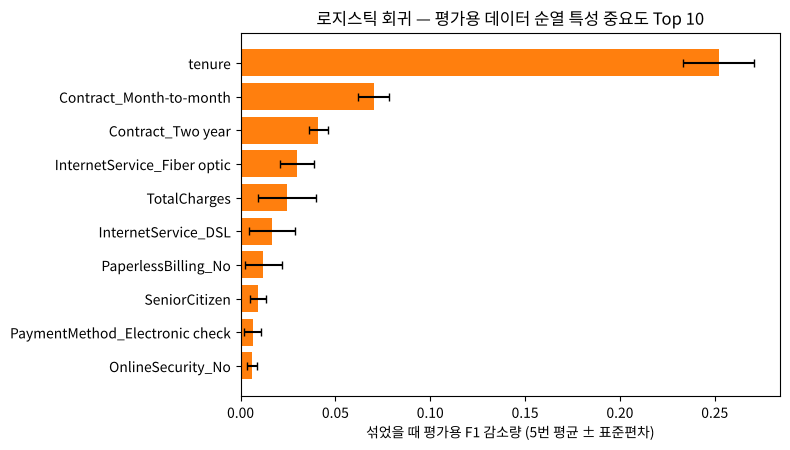

In [7]:
top = df_test_lr_test_imp.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.barh(top['feature'], top['importances'], xerr=top['std'], capsize=3, color='tab:orange')
ax.set_xlabel('섞었을 때 평가용 F1 감소량 (5번 평균 ± 표준편차)')
ax.set_title('로지스틱 회귀 — 평가용 데이터 순열 특성 중요도 Top 10')
plt.tight_layout()
plt.show()

![순열 중요도](./images/05_churn_permutation_top10.png)

음수 27개는 대부분 0 에 가까운 값 — 섞어도 성능이 거의 그대로(우연히 조금 좋아짐)라 **사실상 영향 없는 특성**이다.

**`tenure` 를 섞으면 F1 이 0.25 나 떨어진다** — 다른 특성들(0.07 이하)과 차이가 크다. 그다음이 계약 형태(월 단위 · 2년) · 광랜(Fiber) · 총 요금.

> **📝 고친 부분** (`고객이탈예측 2`)
> - 같은 셀에서 `permutation_importance(...)` 를 **두 번** 계산했다(첫 번째 결과는 쓰지 않음) → 한 번만
> - `feature_names = X_train.columns,` — 끝의 **쉼표** 때문에 컬럼 이름이 아니라 **튜플 `(Index([...]),)`** 이 된다 → 쉼표 제거, 평가용이므로 `X_test.columns`
> - `'importances': feature_importances` → 앞 셀의 **학습용 계수**를 가리키는 다른 변수였다(평가용 중요도가 아님) → `lr_perm_result.importances_mean`
> - `from sklearn.inspection import permutation_importance` 를 두 셀에서 반복 → 한 번
> - 주석 "**SHAP 분석**" → 이 코드는 **순열 중요도**다. SHAP 은 데이터 하나하나의 예측에 각 특성이 얼마나 기여했는지를 게임 이론(Shapley value)으로 나누는 **다른 방법**(`shap` 라이브러리)
> - 그래프 제목 오타 `LogisticRegession` → LogisticRegression, 오타 `평각용` → 평가용

## 4. `n_repeats` — 몇 번 섞어야 할까

In [8]:
rows = []
for n in [1, 5, 10, 30]:
    t = time.time()
    r = permutation_importance(best_lr, X_test, y_test, scoring='f1', n_repeats=n, random_state=0)
    s = pd.Series(r.importances_mean, index=X_test.columns)
    rows.append({'n_repeats': n, '걸린 시간(초)': round(time.time() - t, 2),
                 'tenure': s['tenure'], 'Contract_Month-to-month': s['Contract_Month-to-month'],
                 'TotalCharges': s['TotalCharges']})
pd.DataFrame(rows).round(4)

,n_repeats,걸린 시간(초),tenure,Contract_Month-to-month,TotalCharges
0,1,0.26,0.2239,0.0642,0.0195
1,5,1.55,0.2521,0.0702,0.0245
2,10,2.60,0.2461,0.0665,0.0254
3,30,6.64,0.2390,0.0647,0.0247


![n_repeats 애니메이션](./images/anim_05_n_repeats.gif)

🎬 상위 6개 특성을 1번씩 더 섞을 때마다 점(그 회차의 F1 감소량)이 하나씩 쌓이고, 세로선(평균)이 자리를 잡아 간다. 한 번만 섞으면 운에 따라 값이 출렁이고, **5 ~ 10번** 정도면 평균이 안정된다.

- 걸리는 시간 ≈ **특성 수 × `n_repeats` × 예측 1번** — 메모 "컬럼이 많을수록 실행 속도가 느리다" 가 맞다. 특성이 수백 개면 `n_jobs=-1` 로 병렬 처리.

## 5. 학습용 vs 평가용 — 과대적합 판정 (교재 `모델검증및평가`)

필기는 **학습용 = 계수 크기**, **평가용 = 순열 중요도** 를 비교했다. 그런데 이 모델은 스케일링을 안 했기 때문에 계수 크기가 특성 중요도를 나타내지 못한다([Day 030](../../2026-10-21/)). 공정하게 비교하려면 **같은 방법(순열)** 을 학습용 · 평가용에 각각 적용한다.

In [9]:
coef_abs = pd.Series(np.abs(best_lr.coef_[0]), index=X_train.columns)                  # 필기 : 학습용 계수
perm_train = permutation_importance(best_lr, X_train, y_train, scoring='f1', n_repeats=5, random_state=0)
perm_train = pd.Series(perm_train.importances_mean, index=X_train.columns)              # 학습용 순열
perm_test = pd.Series(lr_perm_result.importances_mean, index=X_test.columns)            # 평가용 순열

rank = lambda s: s.rank(ascending=False).astype(int)
compare = pd.DataFrame({
    '학습용 |계수| 순위 (필기)': rank(coef_abs),
    '학습용 순열 순위': rank(perm_train),
    '평가용 순열 순위': rank(perm_test),
    '평가용 순열 값': perm_test.round(4),
}).sort_values('평가용 순열 순위').head(8)
compare

,학습용 |계수| 순위 (필기),학습용 순열 순위,평가용 순열 순위,평가용 순열 값
tenure,37,1,1,0.2521
Contract_Month-to-month,2,2,2,0.0702
Contract_Two year,1,3,3,0.0411
InternetService_Fiber optic,4,4,4,0.0298
TotalCharges,45,5,5,0.0245
InternetService_DSL,3,7,6,0.0165
PaperlessBilling_No,6,8,7,0.0120
SeniorCitizen,11,18,8,0.0092


| 특성 | 학습용 \|계수\| (필기) | 학습용 순열 | 평가용 순열 |
|---|---|---|---|
| `tenure` | **37위** | **1위** | **1위** |
| `Contract_Month-to-month` | 2위 | 2위 | 2위 |
| `TotalCharges` | **45위** | 5위 | 5위 |

- 필기 방식(계수 vs 순열)으로 보면 `tenure` 가 학습용 37위 → 평가용 1위라 **어긋나 보인다**. 하지만 이건 과대적합이 아니라 **스케일링 안 한 계수**라서 생긴 착시.
- 같은 순열 방식으로 비교하면 학습용 · 평가용 **상위권 순위가 거의 같다** → 교재 기준 **"안정적으로 검증된 모델(일반화 성공)"**.

> **📝 고친 부분** (메모)
> - "학습할 때 데이터와 평가 데이터 다르면 안 된다 / 학습용 데이터와 평가용 데이터가 **다르면 과대적합이 일어난다**" → 반대다. 학습용과 평가용은 **반드시 다른 데이터**여야 한다(같으면 외운 것도 맞혀서 성능이 부풀려진다). 과대적합은 **학습용에서는 잘 맞고 평가용에서는 못 맞히는 것**이고, 특성 중요도로 보면 학습용에서 중요하던 특성이 평가용에서 **폭락 · 음수**가 되는 것이다.
> - "평가용 데이터에 대한 best 모델의 성능 → f1 최대" → best 모델은 평가용이 아니라 **검증 fold 의 F1 이 최대**인 조합이다(GridSearchCV 는 평가용을 보지 않는다, [Day 028](../../2026-10-19/)).

## 6. 정리

| | 내장 중요도 (계수 · `feature_importances_`) | 순열 중요도 (`permutation_importance`) |
|---|---|---|
| 어떤 모델 | 선형 모델(스케일링 필요) · 트리 계열만 | **어떤 모델이든** (SVM · 신경망도) |
| 데이터 | 학습할 때 계산됨 (학습용) | 원하는 데이터 — 보통 **평가용** |
| 비용 | 공짜 (학습하면 나옴) | 특성 수 × `n_repeats` 번 예측 |
| 주의 | 스케일 · 원-핫 중복에 따라 왜곡 | 서로 겹치는 특성(원-핫)은 낮게 나올 수 있음 |

고객 이탈의 핵심 근거 : **가입 기간(`tenure`) > 계약 형태 > 인터넷 서비스(광랜) · 총 요금**.